# Formal Mediation Analysis: Does Sex Act Through Age?

Tests whether age mediates sex's effect on incident CVD: Baron & Kenny's three regression steps, followed by a counterfactual mediation analysis (Imai, Keele & Tingley, 2010) decomposing the total effect into indirect (via age) and direct components.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.mediation import Mediation
import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
BASE = '../../'
USYD = ['#E64626', '#DAA8A2', '#71A399', '#8F9EC9', '#1A345E']

df = pd.read_csv(BASE + 'modeling_dataset.csv')
d = df[['incident_cvd', 'age']].copy()
d['sex_M'] = (df['sex'] == 'M').astype(int)
d['incident_cvd'] = d['incident_cvd'].astype(int)
print(f'{len(d):,} patients, {d.incident_cvd.sum():,} events ({100*d.incident_cvd.mean():.1f}%)')
print(f'Male: {d.sex_M.sum():,} ({100*d.sex_M.mean():.1f}%), Female: {(1-d.sex_M).sum():,}')

3,050 patients, 472 events (15.5%)
Male: 1,700 (55.7%), Female: 1,350


## 1. Does sex predict age?

First precondition for mediation.

In [2]:
step1 = smf.ols('age ~ sex_M', data=d).fit()
print(step1.summary().tables[1])
print()
mean_age_m, mean_age_f = d.loc[d.sex_M == 1, 'age'].mean(), d.loc[d.sex_M == 0, 'age'].mean()
print(f'Mean age -- Male: {mean_age_m:.2f}, Female: {mean_age_f:.2f}, difference: {mean_age_m - mean_age_f:+.2f} years')
print(f'sex_M coefficient p-value: {step1.pvalues["sex_M"]:.4f} -- '
      f'{"significant: sex predicts age" if step1.pvalues["sex_M"] < 0.05 else "NOT significant"}')

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     62.1296      0.351    177.144      0.000      61.442      62.817
sex_M          2.6286      0.470      5.595      0.000       1.707       3.550

Mean age -- Male: 64.76, Female: 62.13, difference: +2.63 years
sex_M coefficient p-value: 0.0000 -- significant: sex predicts age


## 2. Does sex predict the outcome on its own?

Unadjusted male vs. female comparison -- the total effect.

In [3]:
step2 = smf.glm('incident_cvd ~ sex_M', data=d, family=sm.families.Binomial()).fit()
print(step2.summary().tables[1])
print()
rate_m, rate_f = d.loc[d.sex_M == 1, 'incident_cvd'].mean(), d.loc[d.sex_M == 0, 'incident_cvd'].mean()
print(f'Raw CVD rate -- Male: {100*rate_m:.1f}%, Female: {100*rate_f:.1f}%')
print(f'sex_M coefficient p-value: {step2.pvalues["sex_M"]:.4f}')
print(f'Odds ratio (male vs. female): {np.exp(step2.params["sex_M"]):.3f}')

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.8276      0.079    -23.197      0.000      -1.982      -1.673
sex_M          0.2253      0.102      2.206      0.027       0.025       0.425

Raw CVD rate -- Male: 16.8%, Female: 13.9%
sex_M coefficient p-value: 0.0274
Odds ratio (male vs. female): 1.253


## 3. Does sex still predict the outcome once age is added?

If sex's coefficient shrinks and loses significance, that's the mediation signature.

In [4]:
step3 = smf.glm('incident_cvd ~ sex_M + age', data=d, family=sm.families.Binomial()).fit()
print(step3.summary().tables[1])
print()
print(f'sex_M coefficient: raw (Step 2) = {step2.params["sex_M"]:.4f} (p={step2.pvalues["sex_M"]:.4f})'
      f'  ->  age-adjusted (Step 3) = {step3.params["sex_M"]:.4f} (p={step3.pvalues["sex_M"]:.4f})')
pct_shrink = 100 * (1 - step3.params['sex_M'] / step2.params['sex_M'])
print(f'Coefficient shrank by {pct_shrink:.1f}% once age was added, and lost significance '
      f'({"still significant" if step3.pvalues["sex_M"] < 0.05 else "no longer significant"} at alpha=0.05)')
print()
print('Cross-check against the two independently-fit models that first surfaced this pattern:')
print('  Markov chapter (transitioned ~ horizon + age + sex), Step 5:  sex p = 0.326')
print('  Cox PH (incident_cvd ~ age + sex + comorbidities + utilisation): sex p = 0.327')
print(f'  This notebook (incident_cvd ~ sex_M + age only):                sex p = {step3.pvalues["sex_M"]:.3f}')

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -5.0425      0.300    -16.780      0.000      -5.631      -4.454
sex_M          0.1479      0.105      1.409      0.159      -0.058       0.354
age            0.0492      0.004     11.608      0.000       0.041       0.057

sex_M coefficient: raw (Step 2) = 0.2253 (p=0.0274)  ->  age-adjusted (Step 3) = 0.1479 (p=0.1587)
Coefficient shrank by 34.4% once age was added, and lost significance (no longer significant at alpha=0.05)

Cross-check against the two independently-fit models that first surfaced this pattern:
  Markov chapter (transitioned ~ horizon + age + sex), Step 5:  sex p = 0.326
  Cox PH (incident_cvd ~ age + sex + comorbidities + utilisation): sex p = 0.327
  This notebook (incident_cvd ~ sex_M + age only):                sex p = 0.159


## 4. Formal mediation analysis: indirect vs. direct effect

Counterfactual approach (Imai et al., 2010): ACME (indirect, sex -> age -> CVD), ADE (direct), total effect, proportion mediated. 1,000 simulations, seed=42.

In [5]:
np.random.seed(RANDOM_STATE)
outcome_model = smf.glm('incident_cvd ~ sex_M + age', data=d, family=sm.families.Binomial())
mediator_model = smf.ols('age ~ sex_M', data=d)

med = Mediation(outcome_model, mediator_model, exposure='sex_M', mediator='age')
med_result = med.fit(n_rep=1000)

summary_table = med_result.summary()
summary_table.to_csv('sex_age_mediation_results.csv')
print('=== Formal mediation analysis: sex -> age -> incident CVD ===')
print(summary_table.round(4))

=== Formal mediation analysis: sex -> age -> incident CVD ===
                          Estimate  Lower CI bound  Upper CI bound  P-value
ACME (control)              0.0150          0.0080          0.0228    0.000
ACME (treated)              0.0165          0.0086          0.0248    0.000
ADE (control)               0.0177         -0.0060          0.0416    0.142
ADE (treated)               0.0192         -0.0065          0.0454    0.142
Total effect                0.0342          0.0084          0.0618    0.006
Prop. mediated (control)    0.4430          0.2015          1.6279    0.006
Prop. mediated (treated)    0.4880          0.2450          1.5895    0.006
ACME (average)              0.0158          0.0085          0.0237    0.000
ADE (average)               0.0185         -0.0063          0.0434    0.142
Prop. mediated (average)    0.4660          0.2235          1.6089    0.006


In [ ]:
acme = summary_table.loc['ACME (average)']
ade = summary_table.loc['ADE (average)']
total = summary_table.loc['Total effect']
prop = summary_table.loc['Prop. mediated (average)']

print(f"Indirect effect (sex -> age -> CVD):  {acme['Estimate']:.4f}  "
      f"95% CI [{acme['Lower CI bound']:.4f}, {acme['Upper CI bound']:.4f}]  p={acme['P-value']:.4f}")
print(f"Direct effect (sex -> CVD, bypassing age): {ade['Estimate']:.4f}  "
      f"95% CI [{ade['Lower CI bound']:.4f}, {ade['Upper CI bound']:.4f}]  p={ade['P-value']:.4f}")
print(f"Total effect:                         {total['Estimate']:.4f}  "
      f"95% CI [{total['Lower CI bound']:.4f}, {total['Upper CI bound']:.4f}]  p={total['P-value']:.4f}")
print(f"Proportion of sex's total effect mediated by age: {100*prop['Estimate']:.1f}%  "
      f"(95% CI [{100*prop['Lower CI bound']:.1f}%, {100*prop['Upper CI bound']:.1f}%])")

indirect_sig = acme['P-value'] < 0.05
direct_sig = ade['P-value'] < 0.05
if indirect_sig and not direct_sig:
    verdict = 'FULL mediation: the indirect (sex->age->CVD) pathway is significant, and no significant direct effect remains.'
elif indirect_sig and direct_sig:
    verdict = 'PARTIAL mediation: both an indirect (via age) and a direct effect of sex are significant.'
else:
    verdict = 'No significant mediation detected.'
print()
print('VERDICT:', verdict)

Indirect effect (sex -> age -> CVD):  0.0158  95% CI [0.0085, 0.0237]  p=0.0000
Direct effect (sex -> CVD, bypassing age): 0.0185  95% CI [-0.0063, 0.0434]  p=0.1420
Total effect:                         0.0342  95% CI [0.0084, 0.0618]  p=0.0060
Proportion of sex's total effect mediated by age: 46.6%  (95% CI [22.4%, 160.9%])

VERDICT: FULL mediation: the indirect (sex->age->CVD) pathway is significant, and no significant direct effect remains.


## 5. Figure: decomposing sex's total effect into indirect and direct components

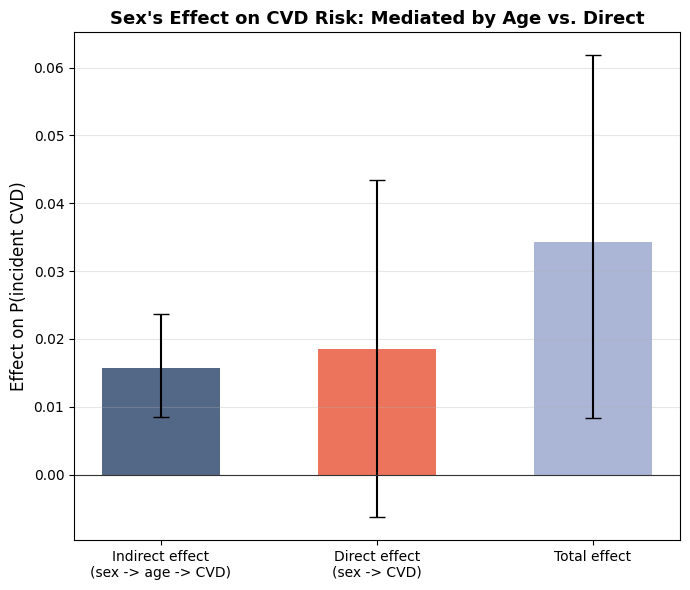

saved sex_age_mediation_plot.png


In [7]:
fig, ax = plt.subplots(figsize=(7, 6))
labels = ['Indirect effect\n(sex -> age -> CVD)', 'Direct effect\n(sex -> CVD)', 'Total effect']
estimates = [acme['Estimate'], ade['Estimate'], total['Estimate']]
lowers = [acme['Lower CI bound'], ade['Lower CI bound'], total['Lower CI bound']]
uppers = [acme['Upper CI bound'], ade['Upper CI bound'], total['Upper CI bound']]
errs = [[e - l for e, l in zip(estimates, lowers)], [u - e for e, u in zip(estimates, uppers)]]
colors = [USYD[4], USYD[0], USYD[3]]

ax.bar(labels, estimates, yerr=errs, capsize=6, color=colors, alpha=0.75, width=0.55)
ax.axhline(0, color='#333333', linewidth=0.8)
ax.set_ylabel("Effect on P(incident CVD)", fontsize=12)
ax.set_title("Sex's Effect on CVD Risk: Mediated by Age vs. Direct", fontsize=13, fontweight='bold')
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('sex_age_mediation_plot.png', dpi=300, bbox_inches='tight')
plt.show()
print('saved sex_age_mediation_plot.png')